In [1]:

import pandas as pd
import numpy as np

# Cargar el dataset de transacciones del mercado
df_trans = pd.read_csv("transacciones_mercado.csv")
print("=== Vista previa de transacciones_mercado.csv ===")
print(df_trans.head())

=== Vista previa de transacciones_mercado.csv ===
  transaccion_id       fecha   hora metodo_pago  total_usd  \
0          T0001  2026-07-26  13:30    Efectivo      12.61   
1          T0002  2026-07-03  12:00    Efectivo      40.60   
2          T0003  2026-07-05  17:30      Cheque      13.22   
3          T0004  2026-06-20  09:15     Tarjeta      22.26   
4          T0005  2026-06-19  15:45    Efectivo      14.23   

                                           productos  
0  Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...  
1  Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...  
2  Yuca; Chicharrón; Repollo; Tomate; Chile Verde...  
3     Yuca; Chicharrón; Repollo; Tomate; Chile Verde  
4  Frijol Rojo; Queso Fresco; Crema Salvadoreña; ...  


# Reto 1: Reglas de Asociación (Patrones de Compra)

In [ ]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configurar Pandas para mostrar todas las columnas 
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 1. separar la cadena de productos por punto y comas
transacciones_lista = df_trans['productos'].dropna().apply(lambda x: [p.strip() for p in x.split(';')]).tolist()

# 2. Aplicar TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transacciones_lista).transform(transacciones_lista)
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Aplicar el algoritmo Apriori (5%)
frequent_itemsets = apriori(df_onehot, min_support=0.05, use_colnames=True)

# 4. Generar reglas de asociación (min_confidence = 0.30 / 30%)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.30)

# Ordenar por Lift de forma descendente y seleccionar las 10 principales
top_rules_limpio = rules.sort_values(by='lift', ascending=False).head(10).copy()

# Limpiar los frozenset para que solo se lean los nombres de los productos de forma limpia
top_rules_limpio['antecedents'] = top_rules_limpio['antecedents'].apply(lambda x: ', '.join(list(x)))
top_rules_limpio['consequents'] = top_rules_limpio['consequents'].apply(lambda x: ', '.join(list(x)))

print(f"=== Total de reglas encontradas: {len(rules)} ===\n")
print("Top 10 Reglas de Asociación (Limpias):")
print(top_rules_limpio[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

=== Total de reglas encontradas: 57812 ===

Top 10 Reglas de Asociación (Limpias):
                                 antecedents                            consequents  support  confidence       lift
7079                      Azúcar, Detergente  Café en Grano, Jabón Lavadero, Aceite    0.065    0.970149  14.699231
7070   Café en Grano, Jabón Lavadero, Aceite                     Azúcar, Detergente    0.065    0.984848  14.699231
3593                      Azúcar, Detergente            Frijol Rojo, Jabón Lavadero    0.064    0.955224  14.695752
3594             Frijol Rojo, Jabón Lavadero                     Azúcar, Detergente    0.064    0.984615  14.695752
18187         Azúcar, Aceite, Jabón Lavadero         Café en Grano, Detergente, Sal    0.064    0.955224  14.695752
18184     Café en Grano, Jabón Lavadero, Sal             Azúcar, Aceite, Detergente    0.064    0.984615  14.695752
7613                      Azúcar, Detergente          Leche, Aceite, Jabón Lavadero    0.064    0.955224 

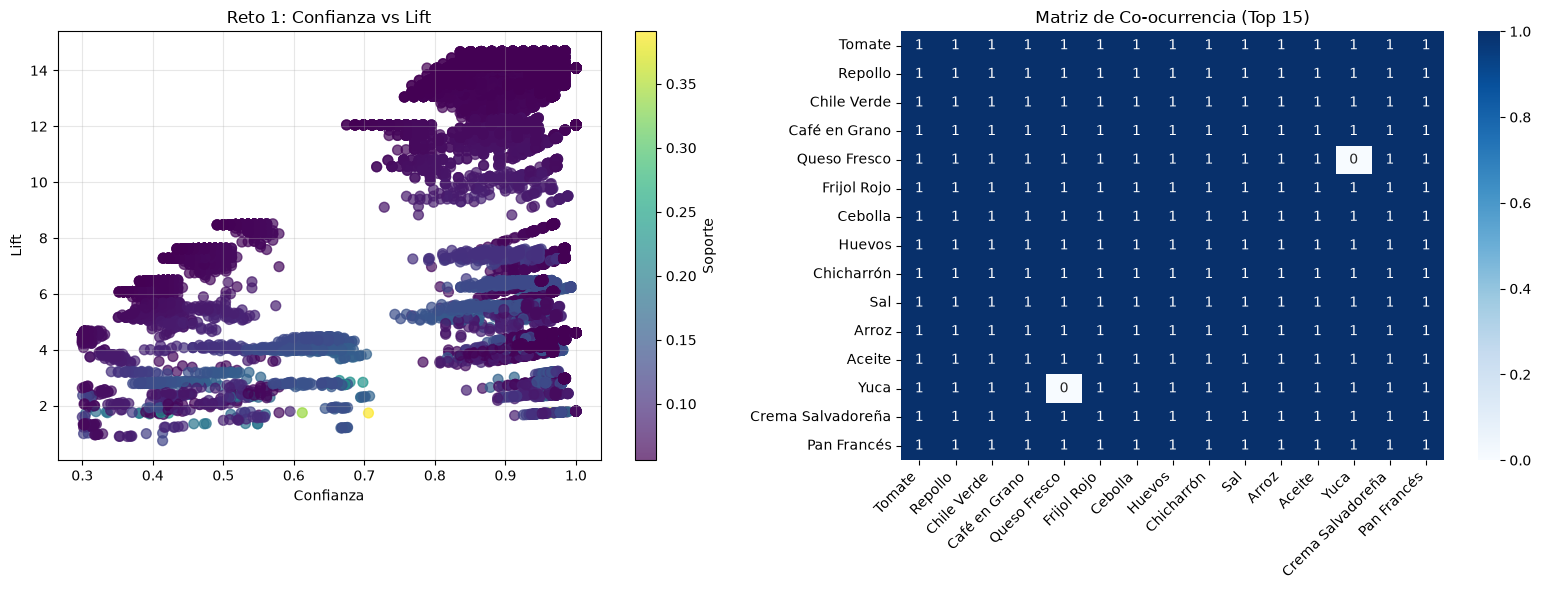

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear 2 columnas para poner las graficas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de dispersión (Scatter Plot): Confianza vs Lift en el primer espacio (izquierda)
scatter = axes[0].scatter(rules['confidence'], rules['lift'], c=rules['support'], cmap='viridis', alpha=0.7, s=50)
fig.colorbar(scatter, ax=axes[0], label='Soporte')
axes[0].set_xlabel("Confianza")
axes[0].set_ylabel("Lift")
axes[0].set_title("Reto 1: Confianza vs Lift")
axes[0].grid(True, alpha=0.3)

# 2. Matriz de Co-ocurrencia (Top 15 Productos) 
co_occurrence_matrix = df_onehot.T.dot(df_onehot)
top_items = df_onehot.sum().nlargest(15).index
co_occ_top = co_occurrence_matrix.loc[top_items, top_items]

sns.heatmap(co_occ_top, annot=True, cmap='Blues', fmt='d', ax=axes[1], cbar=True)
axes[1].set_title("Matriz de Co-ocurrencia (Top 15)")
axes[1].tick_params(axis='x', rotation=45)
# Ajustar etiquetas del eje X para que no se corten
plt.sca(axes[1])
plt.xticks(ha='right')

plt.tight_layout()
plt.show()

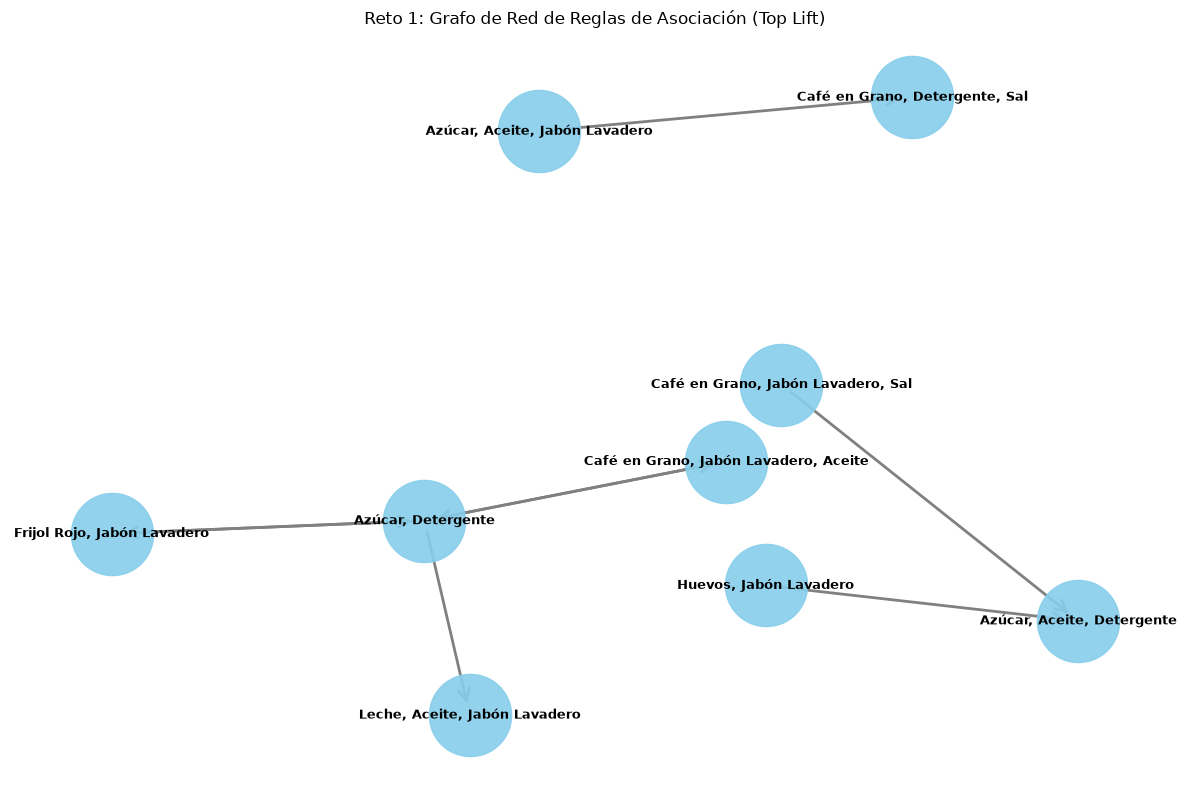

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# Crear un grafo dirigido para las reglas principales
G = nx.DiGraph()

# Tomar las 8 reglas con mayor lift para el grafo
top_8_rules = rules.sort_values(by='lift', ascending=False).head(8)

for index, row in top_8_rules.iterrows():
    antecedent = ', '.join(list(row['antecedents']))
    consequent = ', '.join(list(row['consequents']))
    G.add_edge(antecedent, consequent, support=row['support'], lift=row['lift'])

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.8, seed=42)

# Dibujar nodos y aristas
nx.draw_networkx_nodes(G, pos, node_size=3500, node_color='skyblue', alpha=0.9)
nx.draw_networkx_edges(G, pos, edge_color='gray', arrowstyle='->', arrowsize=20, width=2)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

plt.title("Reto 1: Grafo de Red de Reglas de Asociación (Top Lift)")
plt.axis('off')
plt.tight_layout()
plt.show()

Tres Estrategias de Cross-Selling Derivadas del Reto 1:
1.Estrategia de Ubicación Conjunta Kit de Limpieza y Canasta Básica:

El grafo muestra una fuerte conexión central entre nodos como "Detergente, Azúcar", "Jabón Lavadero", "Aceite" y "Frijol Rojo".

Estrategia: Ubicar físicamente los estantes de productos de limpieza (jabón lavadero, detergente) muy cerca pero tampoco demasiado de los abarrotes básicos (azúcar, aceite y frijol rojo). Como los datos confirman que se compran conjuntamente de forma recurrente, colocar estos productos en pasillos adyacentes facilita que el cliente llene su canasta con ambos sin tener que desplazarse por todo el mercado.

2.Estrategia de Promoción Cruzada para Paquetes de Desayuno:

La matriz de co-ocurrencia y los altos valores de Lift (superiores a 10 y 14 en la gráfica de dispersión) indican reglas con una asociación muy fuerte entre elementos de despensa y café/aceite.

Estrategia: Implementar ofertas del tipo combo en el punto de venta, agrupando por ejemplo "Café en Grano + Azúcar + Aceite" a un precio preferencial. Esto aprovecha la alta afinidad para elevar el ticket promedio de compra por cliente.

3.Estrategia de Exhibición en Línea de Cajas para Artículos de Alta Confianza :

El diagrama de dispersión muestra una alta concentración de reglas con una Confianza superior al 80% (0.8 a 1.0) y Lift elevado.

Estrategia: Colocar productos pequeños de alta predictibilidad de compra conjunta (como sal, café o porciones de azúcar) justo en las zonas de pago o mostradores principales. Al ser productos con una probabilidad de compra casi segura cuando el cliente adquiere su base de productos, tenerlos a la vista en la caja impulsa la venta de última hora.

# Reto 2: Segmentación de Comerciantes (K-Means)


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Cargar el dataset de comerciantes del mercado
df_comerciantes = pd.read_csv("comerciantes_mercado.csv")
print("=== Vista previa de comerciantes_mercado.csv ===")
print(df_comerciantes.head())


=== Vista previa de comerciantes_mercado.csv ===
  comerciante_id          nombre_negocio        rubro  anios_operacion  antiguedad_local ubicacion  empleados  ingreso_mensual_usd  egreso_mensual_usd  m2_local tiene_almacen vende_online acepta_tarjeta horario_extendido  ahorro_previo_usd  deuda_actual_usd  quejas_clientes_3m  edad_comerciante nivel_educativo
0           C001    Los La Unión Viveres     Textiles                5                 2     Norte          1                 2896                2101        11            No           No             Sí                No               2692               583                   4                41          Básico
1           C002  Casa Guadalupe Viveres  Misceláneos               18                 9    Centro          7                 2023                1271        36            Sí           No             Sí                No               6006               661                   4                40          Básico
2           C00

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Preparar las características  del dataset 
var_numericas = ['anios_operacion', 'antiguedad_local', 'empleados', 'ingreso_mensual_usd', 'egreso_mensual_usd']
X_comerciantes = df_comerciantes[var_numericas].dropna()

# Escalar los datos con StandardScaler (media 0, desviación estándar 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_comerciantes)

# 2. Calcular Inercia (Método del Codo) y Coeficiente de Silueta para K de 1 a 7
k_range = range(1, 8)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    
    if k > 1:
        silhouette_scores.append(silhouette_score(X_scaled, labels))
    else:
        silhouette_scores.append(0) # Valor por defecto para K=1 en silueta

# 3. Calcular Gap Statistic c
def calcular_gap_statistic(data, k_range=range(1, 8), n_bootstrap=10):
    gaps = []
    sks = []
    X_min, X_max = np.min(data, axis=0), np.max(data, axis=0)
    
    # Fijar semilla global para el cálculo (evita que tome valores diferentes con cada depuracion)
    np.random.seed(42)
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        w_k = kmeans.inertia_
        
        wkbs = []
        for i in range(n_bootstrap):
            # Semilla controlada para que sea reproducible
            X_uniform = np.random.uniform(X_min, X_max, size=data.shape)
            kmeans_uniform = KMeans(n_clusters=k, random_state=42, n_init=5)
            kmeans_uniform.fit(X_uniform)
            wkbs.append(kmeans_uniform.inertia_)
            
        gap = np.log(np.mean(wkbs)) - np.log(w_k)
        gaps.append(gap)
        sk = np.sqrt(np.mean((np.log(wkbs) - np.mean(np.log(wkbs)))**2))
        sks.append(sk)
        
    return gaps, sks

gaps, sks = calcular_gap_statistic(X_scaled, range(1, 8))

# 4. Encontrar el K óptimo 
# Codo mediante la segunda derivada de las inercias
diffs = np.diff(inertias)
second_diff = np.diff(diffs)
opt_k_elbow = int(np.argmax(np.abs(second_diff)) + 2) if len(second_diff) > 0 else 2

# Silueta máxima (excluyendo K=1)
opt_k_silhouette = int(range(2, 8)[np.argmax(silhouette_scores[1:])])

# Gap Statistic óptimo (criterio formal: gap(k) >= gap(k+1) - s(k+1))
opt_k_gap = 1
for i in range(len(gaps) - 1):
    if gaps[i] >= gaps[i+1] - sks[i+1]:
        opt_k_gap = i + 1
        break

# Se corta sino se a hecho 
if opt_k_gap == 1:
    opt_k_gap = int(np.argmax(gaps) + 1)

# 5. Construir la Tabla 
tabla_comparativa = pd.DataFrame({
    'Método de Selección de K': [
        'Método del Codo', 
        'Coeficiente de Silueta', 
        'Gap Statistic'
    ],
    'K Óptimo Sugerido': [
        opt_k_elbow, 
        opt_k_silhouette, 
        opt_k_gap
    ],
    'Criterio Teórico / Justificación': [
        'Identifica el punto de inflexión o "codo" donde la reducción de la inercia se desacelera.',
        'Busca el valor de K que maximiza la cohesión interna y separación.',
        'Compara la dispersión intra-clúster real .'
    ]
})

print("=" * 95)
print(" TABLA COMPARATIVA DE MÉTODOS DE SELECCIÓN DE K (RETO 2) ")
print("=" * 95)
print(tabla_comparativa.to_string(index=False))
print("=" * 95)

 TABLA COMPARATIVA DE MÉTODOS DE SELECCIÓN DE K (RETO 2) 
Método de Selección de K  K Óptimo Sugerido                                                          Criterio Teórico / Justificación
         Método del Codo                  2 Identifica el punto de inflexión o "codo" donde la reducción de la inercia se desacelera.
  Coeficiente de Silueta                  2                        Busca el valor de K que maximiza la cohesión interna y separación.
           Gap Statistic                  6                                                Compara la dispersión intra-clúster real .


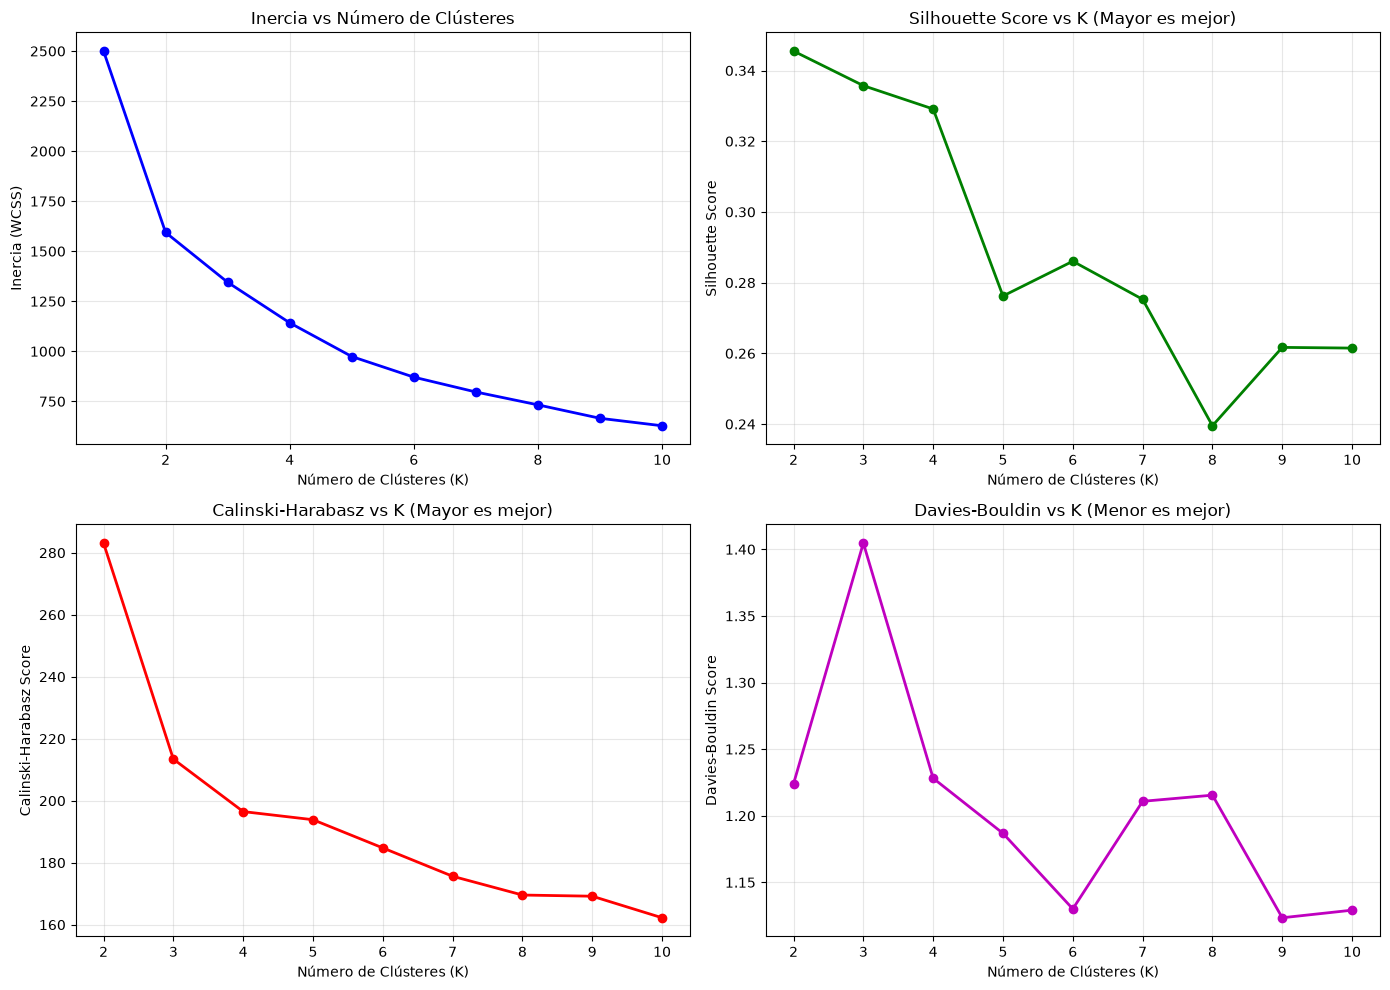

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# 1. Validación completa con múltiples índices (Inercia, Silueta, Calinski-Harabasz, Davies-Bouldin)
def validar_clustering_completo(X_scaled, k_values):
    resultados = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        if k > 1:
            silhouette = silhouette_score(X_scaled, labels)
            calinski = calinski_harabasz_score(X_scaled, labels)
            davies = davies_bouldin_score(X_scaled, labels)
        else:
            silhouette = calinski = davies = np.nan
        resultados.append({
            'K': k,
            'Inercia': kmeans.inertia_,
            'Silhouette': silhouette,
            'Calinski-Harabasz': calinski,
            'Davies-Bouldin': davies
        })
    return pd.DataFrame(resultados)

k_values = range(1, 11)
resultados_validacion = validar_clustering_completo(X_scaled, k_values)

# 2. Visualización de las Métricas de Calidad del Clustering (Lado a lado / Matriz 2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Inercia
axes[0, 0].plot(resultados_validacion['K'], resultados_validacion['Inercia'], 'bo-', linewidth=2, markersize=6)
axes[0, 0].set_xlabel('Número de Clústeres (K)')
axes[0, 0].set_ylabel('Inercia (WCSS)')
axes[0, 0].set_title('Inercia vs Número de Clústeres')
axes[0, 0].grid(True, alpha=0.3)

# Gráfico 2: Silhouette Score
axes[0, 1].plot(resultados_validacion['K'][1:], resultados_validacion['Silhouette'][1:], 'go-', linewidth=2, markersize=6)
axes[0, 1].set_xlabel('Número de Clústeres (K)')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].set_title('Silhouette Score vs K (Mayor es mejor)')
axes[0, 1].grid(True, alpha=0.3)

# Gráfico 3: Calinski-Harabasz
axes[1, 0].plot(resultados_validacion['K'][1:], resultados_validacion['Calinski-Harabasz'][1:], 'ro-', linewidth=2, markersize=6)
axes[1, 0].set_xlabel('Número de Clústeres (K)')
axes[1, 0].set_ylabel('Calinski-Harabasz Score')
axes[1, 0].set_title('Calinski-Harabasz vs K (Mayor es mejor)')
axes[1, 0].grid(True, alpha=0.3)

# Gráfico 4: Davies-Bouldin
axes[1, 1].plot(resultados_validacion['K'][1:], resultados_validacion['Davies-Bouldin'][1:], 'mo-', linewidth=2, markersize=6)
axes[1, 1].set_xlabel('Número de Clústeres (K)')
axes[1, 1].set_ylabel('Davies-Bouldin Score')
axes[1, 1].set_title('Davies-Bouldin vs K (Menor es mejor)')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Entrenamiento final usando K-Means+ con el óptimo analítico K=3
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, init='k-means++', n_init=10)
df_comerciantes['cluster'] = kmeans_final.fit_predict(X_scaled)



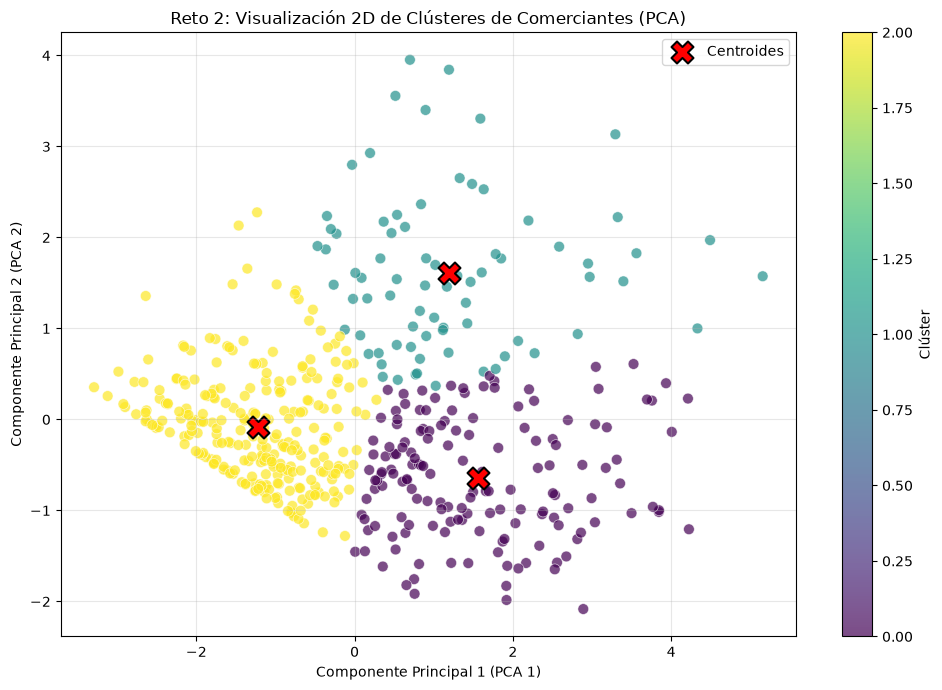


 TABLA DE PERFILAMIENTO DE CADA CLÚSTER 
 cluster  Tamano_Comerciantes  Ingreso_Promedio_USD  Egreso_Promedio_USD  Anios_Operacion_Prom  Antiguedad_Local_Prom  Empleados_Prom
       0                  154           3555.123377          2496.967532             16.233766               3.616883        3.129870
       1                   76           2740.697368          1883.578947             18.815789              10.342105        2.539474
       2                  270           1905.611111          1339.288889              5.566667               2.470370        1.574074


In [8]:
from sklearn.decomposition import PCA

# 1. Reducción de dimensionalidad a 2 componentes principales con PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Obtener las coordenadas PCA de los centroides finales
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

# 2. Visualización 2D de los clústeres
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_comerciantes['cluster'], cmap='viridis', alpha=0.7, s=60, edgecolors='w', linewidth=0.5)

# Graficar los centroides con una X roja
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=250, c='red', label='Centroides', edgecolors='black', linewidth=1.5)

plt.xlabel('Componente Principal 1 (PCA 1)')
plt.ylabel('Componente Principal 2 (PCA 2)')
plt.title('Reto 2: Visualización 2D de Clústeres de Comerciantes (PCA)')
plt.colorbar(scatter, label='Clúster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Tabla de Perfilamiento por Clúster (Tamaño y promedios solicitados)
perfil_cluster = df_comerciantes.groupby('cluster').agg(
    Tamano_Comerciantes=('comerciante_id', 'count'),
    Ingreso_Promedio_USD=('ingreso_mensual_usd', 'mean'),
    Egreso_Promedio_USD=('egreso_mensual_usd', 'mean'),
    Anios_Operacion_Prom=('anios_operacion', 'mean'),
    Antiguedad_Local_Prom=('antiguedad_local', 'mean'),
    Empleados_Prom=('empleados', 'mean')
).reset_index()

print("\n" + "="*80)
print(" TABLA DE PERFILAMIENTO DE CADA CLÚSTER ")
print("="*80)
print(perfil_cluster.to_string(index=False))
print("="*80)

In [9]:
# Análisis de estabilidad para K=3
def analizar_estabilidad_kmeans(X_scaled, k_optimo=3, n_iteraciones=20):
    resultados_estabilidad = []
    for i in range(n_iteraciones):
        kmeans = KMeans(n_clusters=k_optimo, random_state=i, n_init=1)
        labels = kmeans.fit_predict(X_scaled)
        resultados_estabilidad.append({
            'ejecucion': i,
            'inercia': kmeans.inertia_,
            'centroides': kmeans.cluster_centers_
        })
    
    inercias = [r['inercia'] for r in resultados_estabilidad]
    variabilidad_inercia = np.std(inercias) / np.mean(inercias)
    
    centroides_ref = resultados_estabilidad[0]['centroides']
    variabilidades_centroides = []
    for i in range(1, n_iteraciones):
        centroides_actual = resultados_estabilidad[i]['centroides']
        distancias = np.linalg.norm(centroides_ref - centroides_actual, axis=1)
        variabilidades_centroides.append(np.mean(distancias))
        
    var_prom_centroides = np.mean(variabilidades_centroides)
    return variabilidad_inercia, var_prom_centroides

var_inercia, var_centroides = analizar_estabilidad_kmeans(X_scaled, k_optimo=3, n_iteraciones=20)

print("="*60)
print(" ANÁLISIS DE ESTABILIDAD DEL CLUSTERING (K=3) ")
print("="*60)
print(f"• Desviación / Variabilidad relativa de la Inercia: {var_inercia:.6f}")
print(f"• Variabilidad promedio de los Centroides:        {var_centroides:.6f}")
if var_inercia < 0.01:
    print(" Estado: ESTABLE (Inercias consistentes)")
else:
    print(" Estado: MODERADAMENTE VARIABLE (Sensible a inicialización)")
print("="*60)

 ANÁLISIS DE ESTABILIDAD DEL CLUSTERING (K=3) 
• Desviación / Variabilidad relativa de la Inercia: 0.006108
• Variabilidad promedio de los Centroides:        1.838117
 Estado: ESTABLE (Inercias consistentes)


Programas de Apoyo Basados en el Perfil de cada Clúster 
1. Para el Clúster 0: Programa de Aceleración Comercial y Digitalización

Es un grupo maduro y sólido (154 comerciantes), caracterizado por tener los ingresos más altos (promedio de $3,555.12 USD), un buen número de años de operación (16.2 años) y un equipo de trabajo más amplio (~3.1 empleados).   

 Debido a que este grupo cuenta con estabilidad financiera y capacidad operativa, el programa se enfocará en proporcionarles herramientas de optimización avanzada, automatización de inventarios, gestión digital de cobros y estrategias de expansión comercial para potenciar su crecimiento dentro del mercado.
 
2. Para el Clúster 1: Programa de Modernización de Infraestructura
  Es el grupo más antiguo y arraigado (76 comerciantes), con el promedio más alto de antigüedad en el local (10.3 años) y de años de operación (18.8 años), manteniendo ingresos moderados de $2,740.70 USD.   
   
   Al ser los locatarios con mayor arraigo histórico en el mercado pero con márgenes estables, el programa debe centrarse en mejoras de infraestructura, mantenimiento de sus puestos tradicionales, acceso a fondos de respaldo para infraestructura y capacitación  para proteger su patrimonio comercial de larga duración.

3. Para el Clúster 2: Programa de Capital Semilla, Mentoría y Rescate Financiero Básico
Es el grupo mayoritario (270 comerciantes), pero el más vulnerable: presenta los ingresos más bajos ($1,905.61 USD), pocos años de operación (5.5 años), menor antigüedad en el local (2.4 años) y un equipo reducido (~1.5 empleados).  

 Al tratarse de los comerciantes más nuevos y con menores recursos económicos para sostener sus egresos, requieren un programa urgente de microcréditos con tasas blandas, subsidios de apoyo inicial, y talleres prácticos de control básico de ingresos y egresos para asegurar su supervivencia y evitar el riesgo de quiebra.

# Reto 3: Predicción de Quiebra de Comerciantes (Árboles de Decisión)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# 1. Cargar el dataset de quiebra del mercado
df_quiebra = pd.read_csv("quiebra_mercado.csv")

print("=== VISTA PREVIA DE QUIEBRA_MERCADO.CSV ===")
print(df_quiebra.head())
print("\nInformación del dataset:")
print(df_quiebra.info())

# Detectar automáticamente la última columna del DataFrame
columna_objetivo = df_quiebra.columns[-1]
print(f"\nDistribución de la variable objetivo ('{columna_objetivo}'):")
print(df_quiebra[columna_objetivo].value_counts())

=== VISTA PREVIA DE QUIEBRA_MERCADO.CSV ===
  registro_id comerciante_id  anios_operacion          rubro ubicacion  ingreso_promedio_3m_usd  variacion_ingreso_pct  deuda_actual_usd  ahorro_previo_usd tiene_seguro recibio_credito_pandemia  pandemia_caida_ventas_pct  post_pandemia_recuperacion_pct  edad_comerciante nivel_educativo  numero_empleados  ventas_diarias_promedio  clientes_diarios  margen_ganancia_pct  quiebra_6m
0       R0001           C042                8      Panadería    Centro                     2977                   9.37               553              12998           No                       Sí                      46.60                           76.16                50           Medio                 2                        6                17                42.00           0
1       R0002           C160               12  Comida Rápida      Este                     5115                 -39.36               436              23525           No                       Sí 

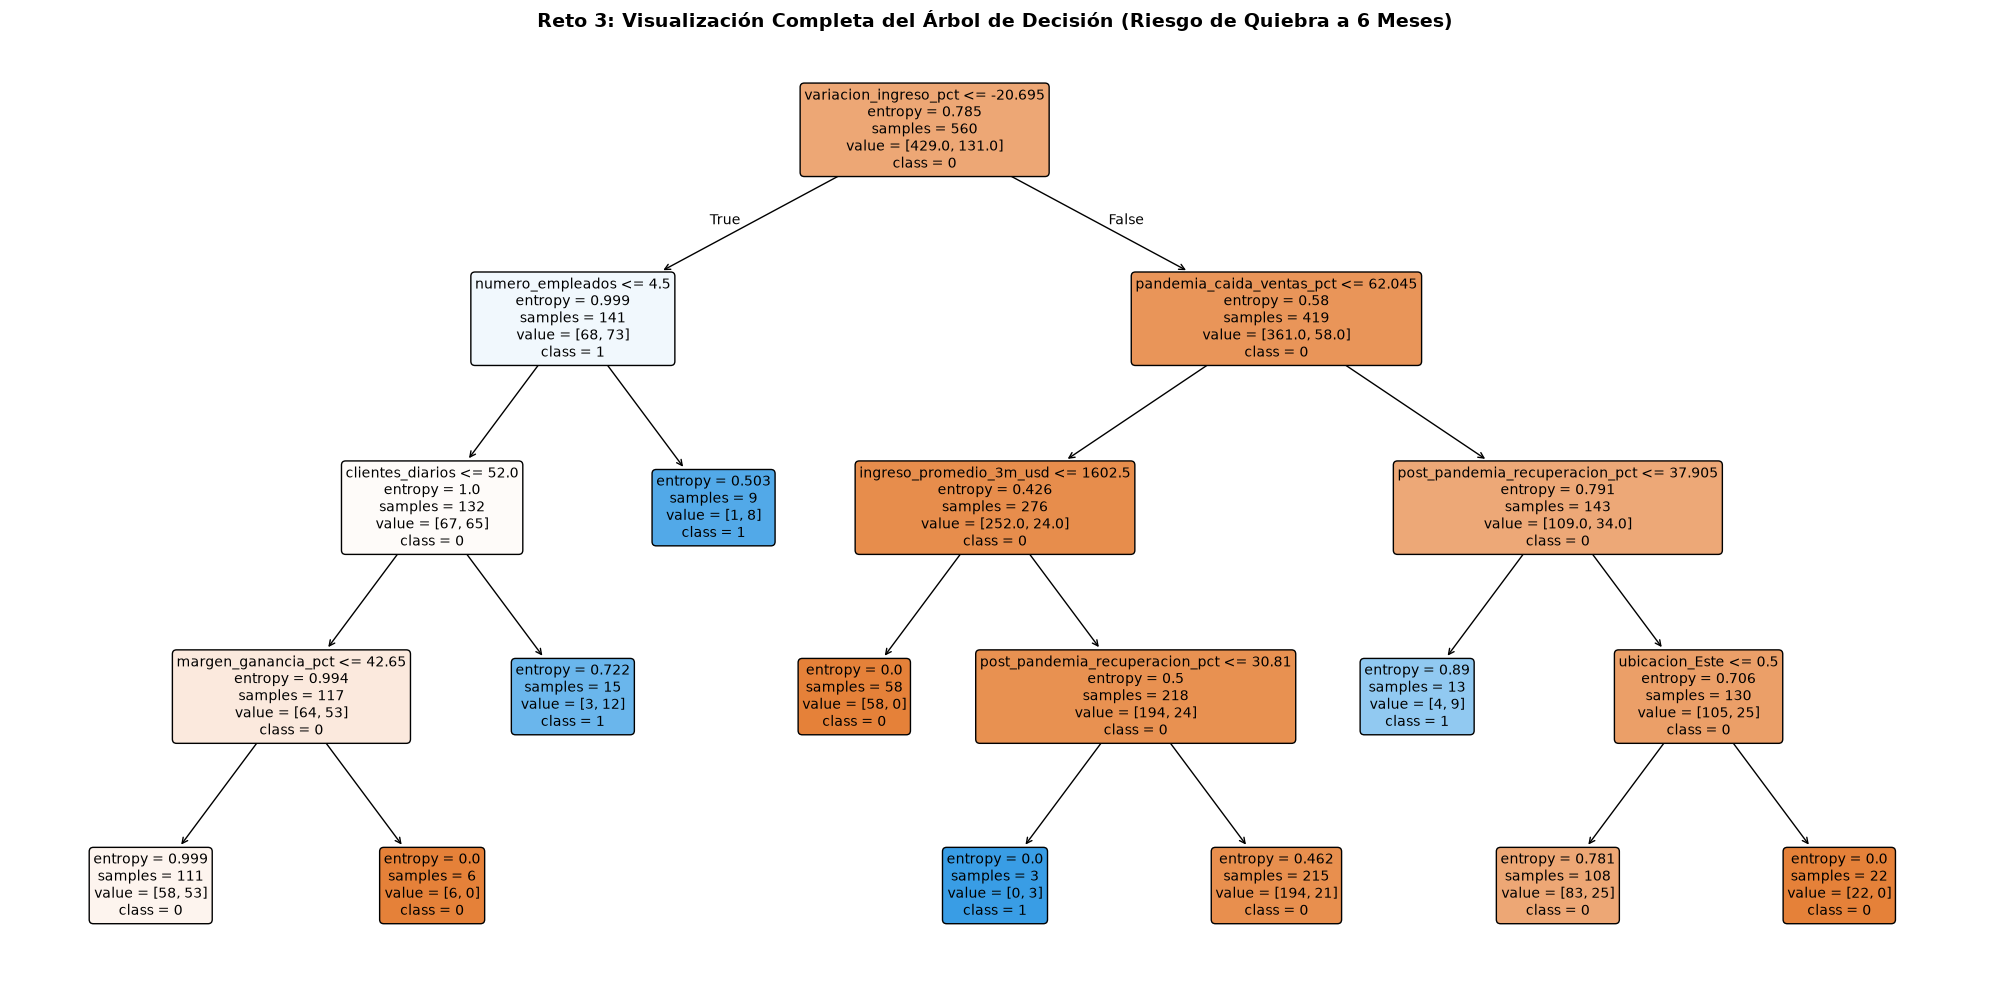

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Cargar el dataset y definir la variable objetivo detectada
df_quiebra = pd.read_csv("quiebra_mercado.csv")
columna_objetivo = 'quiebra_6m'

# 2. Preprocesamiento: Excluir identificadores
columnas_a_excluir = [c for c in ['registro_id', 'comerciante_id'] if c in df_quiebra.columns]
df_modelo = df_quiebra.drop(columns=columnas_a_excluir)

df_encoded = pd.get_dummies(df_modelo, drop_first=True)

X = df_encoded.drop(columna_objetivo, axis=1)
y = df_encoded[columna_objetivo]

# 3. División de datos (70% entrenamiento / 30% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Entrenar el Árbol de Decisión (limitando max_depth para que el gráfico sea legible y analizable)
clf_quiebra = DecisionTreeClassifier(max_depth=4, min_samples_split=20, criterion='entropy', random_state=42)
clf_quiebra.fit(X_train, y_train)

# 5. Visualización completa del árbol de decisión entrenado
plt.figure(figsize=(20, 10))
plot_tree(
    clf_quiebra, 
    feature_names=X.columns, 
    class_names=[str(c) for c in clf_quiebra.classes_],
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title("Reto 3: Visualización Completa del Árbol de Decisión (Riesgo de Quiebra a 6 Meses)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


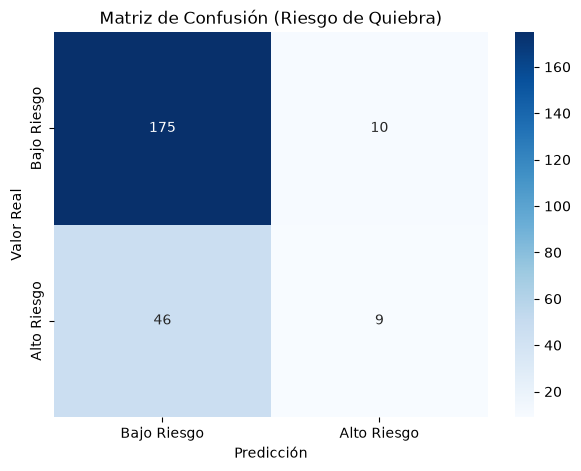

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

 Bajo Riesgo       0.79      0.95      0.86       185
 Alto Riesgo       0.47      0.16      0.24        55

    accuracy                           0.77       240
   macro avg       0.63      0.55      0.55       240
weighted avg       0.72      0.77      0.72       240



In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Generar predicciones con el modelo entrenado previamente
y_pred = clf_quiebra.predict(X_test)

# Definir etiquetas en español solicitadas
nombres_clases = ["Bajo Riesgo", "Alto Riesgo"]

# 2. Matriz de Confusión como mapa de calor con Seaborn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=nombres_clases, 
            yticklabels=nombres_clases)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión (Riesgo de Quiebra)')
plt.show()

# 3. Reporte de Clasificación completo en español
print("=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_test, y_pred, target_names=nombres_clases))



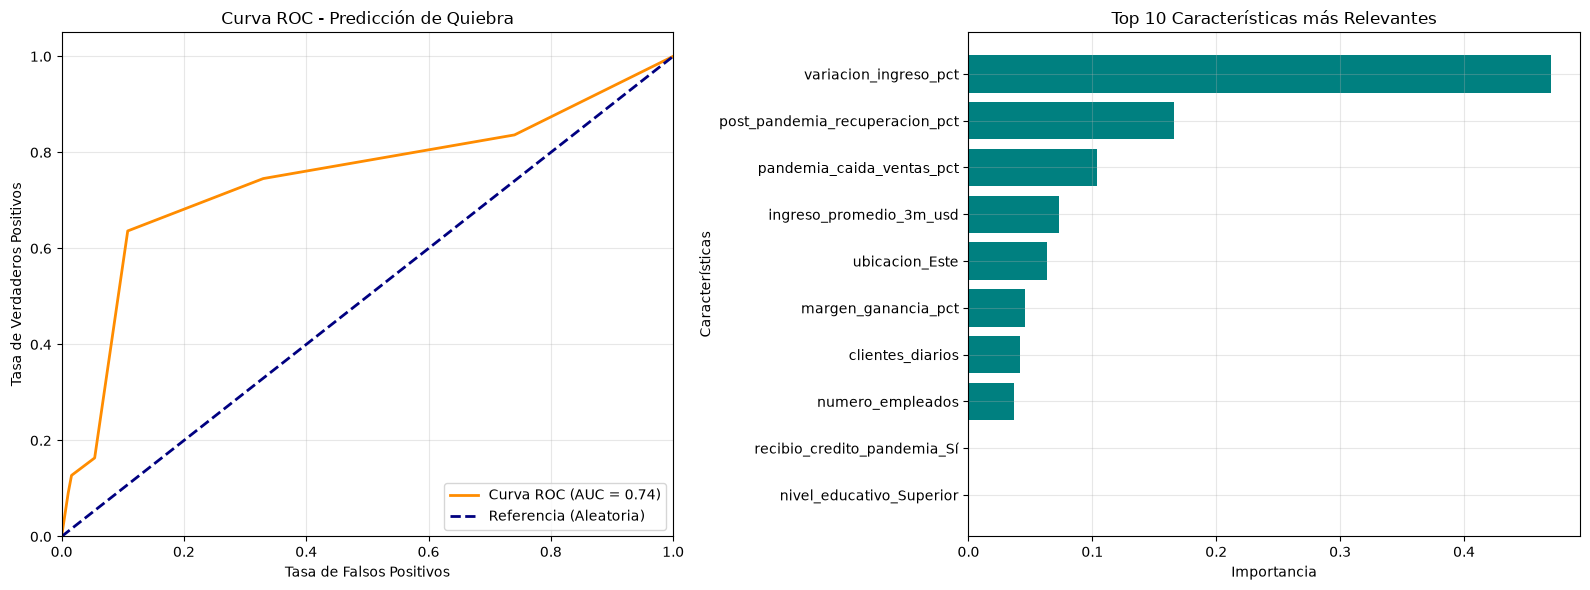

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve, auc

# Crear una figura con 2graficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- 1. GRÁFICO DE LA CURVA ROC ---
y_prob = clf_quiebra.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Referencia (Aleatoria)')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('Tasa de Falsos Positivos')
ax1.set_ylabel('Tasa de Verdaderos Positivos')
ax1.set_title('Curva ROC - Predicción de Quiebra')
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# --- 2. GRÁFICO DE BARRAS HORIZONTALES (Top 10 Características) ---
importancias = pd.DataFrame({'Caracteristica': X.columns, 'Importancia': clf_quiebra.feature_importances_})
importancias = importancias.sort_values(by='Importancia', ascending=True).tail(10)

ax2.barh(importancias['Caracteristica'], importancias['Importancia'], color='teal')
ax2.set_xlabel('Importancia')
ax2.set_ylabel('Características')
ax2.set_title('Top 10 Características más Relevantes')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

1. Reglas de Negocio Extraídas del Árbol de Decisión

Regla 1 (Alerta por Variación de Ingresos y Personal):
   Si la variación de ingreso es menor o igual a -20.7% Y el número de empleados es menor o igual a 4.
  Como resultado se tiene un Alto Riesgo.
  Interpretacion:Comerciantes con caídas severas en sus ingresos y equipos de trabajo pequeños entran de inmediato en zona crítica de quiebra.

Regla 2 (Vulnerabilidad por Bajo Flujo de Clientes)
  Si la variación de ingreso es menor o igual a -20.7%, el número de empleados es mayor a 4, Y los clientes diarios son menores o iguales a 52.
   Como resultado se tiene Alto Riesgo.
  Interpretación: Aunque el local tenga más personal, una baja en ingresos sumada a un flujo reducido de clientes diarios eleva drásticamente la probabilidad de quiebra.

Regla 3 (Riesgo por Estancamiento Post-Pandemia):
  Si la caída de ventas en pandemia fue mayor al 62% Y la recuperación post-pandemia es menor o igual al 37.9%.
  Como resultado se tiene Alto Riesgo.
  Interpretación: Los comerciantes que sufrieron un fuerte impacto en la crisis sanitaria y no han logrado repuntar sus ventas muestran una alta vulnerabilidad financiera.

----------------------------------------------------------------------------------------------------------------------------------

2. Recomendaciones de Intervención para Alto Riesgo

Recomendación 1: Programa de Estabilización de Ingresos 
  Variable principal: Variación de ingreso porcentual.
  Intervención:Facilitar microcréditos de emergencia a tasa preferencial o diferimiento de pagos para locatarios con caídas abruptas en sus ingresos trimestrales.

Recomendación 2: Estrategias de Atracción y Aumento de Tráfico de Compradores
  Variables principales: Clientes diarios y número de empleados.
  Intervención: Diseñar ferias comerciales, promociones conjuntas en el mercado y señalización en pasillos para derivar flujo de visitantes hacia los locales con baja afluencia.

Recomendación 3: Plan de Recuperación Comercial Post-Pandemia
  Variables principales: Caída de ventas en pandemia y porcentaje de recuperación.
  Intervención: Brindar asistencia técnica en modernización de productos, venta digital y diversificación a los comerciantes que quedaron rezagados tras la pandemia.

In [ ]:
import sys
import pandas as pd
import mlxtend

print("Versión de Python:", sys.version)
print("Versión de Pandas:", pd.__version__)
print("Versión de Mlxtend:", mlxtend.__version__)